**Bitácora · Day 3 PrefixSpan (chestpain)**

- **v1** `Day3_prefixspan_v1`  
  PrefixSpan on group tags, visits kept; KMeans clusters + SPADE. *Files:* `patterns_chestpain.json`
- **v2** `Day3_prefixspan_v2`  
  Motifs per visit-pruned NMF component; psych-vs-troponin timing. *Files:* `nmf_k8_chestpain_v2.npz`
- **v3 hybrid** `Day3_prefixspan_v3_hybrid` (2026-10-06) ← **this notebook**  
  v2 + deterministic ties, held-out pass rate, same-day flag, Excel export. *Files:* `nmf_k8_chestpain_v2.npz`, `Day3_v3_hybrid_top3_patterns_table.xlsx`
- **v3 concept** `Day3_prefixspan_v3_concept` (2026-10-07)  
  Hybrid on concept-level tokens; k=7 bundles named directly (v2 matching only for other k). *Files:* `nmf_k8_chestpain_v3.npz`, `Day3_v3_concept_final_table_chestpain_k{K}.xlsx`, `token_map_chestpain_concept.csv`

# Day 3 · v3 hybrid — sequence motifs inside the visit-pruned NMF components (dx_9487)

**Today's goal:** mine ordered motifs *within each of the 8 NMF components* from `Day1_nmf_v2`,
on event streams with every visit event removed (care-driven bias). Same PrefixSpan as v1; what
changes is the input (no visit tokens) and the groups (v2 components instead of KMeans clusters).

Why: Day 1 v2 told us *which codes co-occur*; the open question from the review is *in what order*
for the two competing explanations of dx_9487 (cardiac workup vs anxiety/panic), and whether any
bundle is really about the condition rather than the care setting.


> **v3 hybrid = this v2 notebook + three additions; v2 itself is untouched.** (Same additions as the letrozole hybrid; the `motif_robustness` helpers are imported from `../repr_learn_letrozole`.)
> 1. **Deterministic ties** — PrefixSpan counts and every sort break ties on the pattern, so two runs give the same motifs.
> 2. **Section 2c · held-out pass rate** — share of 20 random 50/50 splits × 2 directions (40 runs) in which a motif still passes on the half it was *not* scored on; also family-level (near-duplicates vote as one).
> 3. **Same-day flag** — support re-counted with a strictly-later-date rule; a motif whose support collapses is a same-day bundle (co-occurrence), not an evidenced order.
> A final cell writes the top-3 patterns table to Excel. v2 has no bootstrap / re-test columns for this cohort, so the table has no lift range or re-test count.

In [1]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)
import ethos_omop as eo

OUT_DIR = "../../inputs/chest_pain_cohort/"   # matches Day 1's extract_cohort() output dir
DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']   # Visit stays in the load so we can show before vs after

if not os.path.isdir(OUT_DIR):
    raise FileNotFoundError(
        f"{OUT_DIR}/ not found. Run Day 1's eo.extract_cohort(...) (or "
        f"eo.extract_omop(...) with OUT_DIR='omop_extract') first, or "
        f"python make_demo_extract.py for a synthetic stand-in.")

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=False)
raw      = eo.load_events(OUT_DIR, domains=DOMAINS)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

# v2: drop every visit event BEFORE tagging (same rule as Day1_nmf_v2): a row is a visit if its
# domain OR vocabulary is "visit".
is_visit = (raw['domain'].astype(str).str.lower().eq('visit')
            | raw['vocabulary_id'].astype(str).str.lower().eq('visit'))
visit_ids = set(raw.loc[is_visit, 'concept_id'])
events   = eo.tag_events(raw[~is_visit].reset_index(drop=True), codesets)

tbl = (pd.DataFrame({'before': raw['domain'].value_counts(), 'after': events['domain'].value_counts()})
         .fillna(0).astype(int))
tbl.loc['TOTAL'] = [len(raw), len(events)]
tbl['removed_%'] = ((1 - tbl['after'] / tbl['before']) * 100).round(1)
print("events per domain, BEFORE vs AFTER visit pruning")
print(tbl.to_string())
print(f"\npatients: {raw.person_id.nunique():,} -> {events.person_id.nunique():,}")
print("curated codeset tags on visit concepts (now absent):",
      sorted(t for t, ids in codesets.items() if set(ids) & visit_ids) or "none")
del raw                                              # free memory

print(f"\nevents {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)


events per domain, BEFORE vs AFTER visit pruning
               before     after  removed_%
domain                                    
Condition    19065530  19065530        0.0
Drug          7476972   7476972        0.0
Measurement   8438628   8438628        0.0
Procedure    11544654  11544654        0.0
Visit        12162137         0      100.0
TOTAL        58687921  46525784       20.7

patients: 139,416 -> 139,416
curated codeset tags on visit concepts (now absent): ['ed_visit']

events (46525784, 11)   patients 139416
codeset coverage: 9.2% of events carry a clinical tag
truth labels: ABSENT (real data)


,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,tag,in_codeset
0,22,2212095,2019-04-25,Measurement,CPT4,80061,Lipid panel This panel must include the follow...,CPT4,CPT4/80061,lipid_panel_this_pan__cpt4__2212095,False
1,22,2212320,2019-04-25,Measurement,CPT4,82670,Estradiol; total,CPT4,CPT4/82670,estradiol_total__cpt4__2212320,False
2,22,2212816,2019-04-25,Measurement,CPT4,86376,"Microsomal antibodies (eg, thyroid or liver-ki...",CPT4,CPT4/86376,microsomal_antibodie__cpt4__2212816,False
3,22,4017355,2019-04-25,Measurement,SNOMED,104994008,"Triiodothyronine, free measurement",Procedure,SNOMED/104994008,triiodothyronine_fre__procedure__4017355,False
4,22,4068735,2019-04-25,Measurement,SNOMED,20436004,"Testosterone measurement, unbound",Procedure,SNOMED/20436004,testosterone_measure__procedure__4068735,False
5,22,4196731,2019-04-25,Measurement,SNOMED,313408009,Total thyroxine measurement,Procedure,SNOMED/313408009,total_thyroxine_meas__procedure__4196731,False


In [2]:
seqs = eo.sequences(events, col='tag', dedup_same_day=True, collapse_repeats=True)
pids = sorted(seqs)
db   = [seqs[p] for p in pids]

print("example timeline:")
print(' -> '.join(db[1][:12]))
print("\nmedian sequence length:", int(np.median([len(s) for s in db])))

example timeline:
acute_upper_respirat__disorder__257011 -> impacted_cerumen__disorder__374375 -> removal_impacted_cer__cpt4__42627985 -> infectious_agent_ant__cpt4__2213181 -> umbilical_hernia__disorder__4245842 -> periodic_comprehensi__cpt4__2514528 -> general_examination___procedure__4036803 -> incisional_hernia__disorder__198464 -> palpitations__clinical_finding__315078 -> abnormal_findings_di__clinical_finding__435081 -> ekg -> esophageal_intubatio__cpt4__42738687

median sequence length: 166


### The preprocessing decisions, restated

The first two live in `eo.sequences()` and both are arbitrary:

1. **Same-day ties.** Claims carry a date, not a timestamp, so `DOMAIN_ORDER` breaks ties.
   Visit, condition, procedure, measurement, drug, observation.
2. **Refill collapsing.** Consecutive repeats of the same tag become one token, otherwise
   every pattern is `metformin -> metformin -> metformin`. Chronicity is real signal, so
   capture it as a separate feature — fill count, days supply — not as sequence position.
3. **Visits are not in the sequence at all (v2).** They were the most common tokens in v1 and
   made every motif list a chain of pharmacy / office / ED visits. Dropping them removes that
   care-setting bias; it also removes the `ed_visit` tag, so any motif that depended on "went to the
   ED" is invisible here by construction.

## 1 · PrefixSpan, implemented


In [3]:
import collections

def prefixspan(db, min_sup, max_len=4):
    """Minimal PrefixSpan over single-item sequences.

    db      : list of lists of tokens
    min_sup : minimum number of sequences containing the pattern
    returns : DataFrame of (pattern, support, support_pct)
    """
    n, results = len(db), []

    def scan(projected, prefix):
        counts = collections.Counter()
        for seq in projected:
            for item in sorted(set(seq)):                   # count each sequence once
                counts[item] += 1
        for item, c in counts.items():
            if c < min_sup:
                continue
            new_prefix = prefix + [item]
            results.append((tuple(new_prefix), c))
            if len(new_prefix) >= max_len:
                continue
            # project: keep the suffix after the FIRST occurrence of item
            nxt = [seq[seq.index(item) + 1:] for seq in projected if item in seq]
            if nxt:
                scan(nxt, new_prefix)

    scan([list(s) for s in db], [])
    return (pd.DataFrame(results, columns=['pattern', 'support'])
              .assign(support_pct=lambda d: (d.support / n * 100).round(1)))

## 2 · Discriminative mining — motifs per NMF component

Raw support finds whatever is common, which is mostly ambient care. What you want is patterns
common **inside** a group and rare **outside** it. Here the groups are the **8 NMF components of
`Day1_nmf_v2`** (k=8, visits pruned; stable on 4+ of 5 splits).

What the v2 loadings showed, so the motifs below can be read against it:

- **c3 acute / ED workup** owns `troponin` (62%, rank 1); **c0 outpatient cardiometabolic workup** owns
  `ekg`, `stress_test`, `hba1c`, `t2dm`. `cad` and `coronary_angio` are split between the two.
- **No anxiety / panic bundle exists**: `anxiety` is spread 10-22% over c0, c2, c3, c7;
  `panic_attack` sits in c3 (28%) and c7 (27%). `ssri` / `benzodiazepine` load on the prescription
  bundle c1, but so do `beta_blocker` and `statin`.
- **c4** is the GI / screening bundle that owns `gerd`.

Day 3 asks what order those codes come in, per component.


In [4]:
from scipy import sparse as sp
from sklearn.decomposition import NMF

# Rebuild Day1_nmf_v2's k=8 NMF exactly (same prevalence floor, same anchor drop, same NMF_KW; nndsvd
# init is deterministic), so component numbers match its loadings tables. Day1_nmf_v2 writes the
# cache file below; if it is missing or stale (different extract / floor) this cell fits and saves it.
n_pat      = events.person_id.nunique()
N_TRAIN    = min(20_000, int(0.6 * n_pat))
MIN_PAT    = int(np.ceil(5 * n_pat / N_TRAIN))
prev_pat   = events.groupby('tag').person_id.nunique()
KEEP_TAGS  = prev_pat.index[prev_pat >= MIN_PAT]
nmf_cols   = KEEP_TAGS.drop('chest_pain')                # cohort anchor, 100% prevalence
CACHE      = "nmf_k8_chestpain_v2.npz"                   # same file Day1_nmf_v2 writes

z = np.load(CACHE) if os.path.exists(CACHE) else None
if z is not None and (set(z['cols']) != set(nmf_cols)
                      or set(z['pids']) != set(events.person_id.unique())):
    z = None

if z is not None:
    H   = pd.DataFrame(z['H'], columns=z['cols'])
    lab = pd.Series(z['labels'], index=z['pids'])
    print(f"NMF k=8 loaded from {CACHE}")
else:
    Xb   = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)
    Xs   = sp.csr_matrix(Xb[nmf_cols].to_numpy()).astype(float)
    nmf  = NMF(n_components=8, init='nndsvd', random_state=0, max_iter=2000, tol=1e-4).fit(Xs)
    H    = pd.DataFrame(nmf.components_, columns=nmf_cols)
    lab  = pd.Series(nmf.transform(Xs).argmax(1), index=Xb.index)
    np.savez(CACHE, H=H.to_numpy(), cols=np.array(H.columns, dtype=str), pids=lab.index.to_numpy(),
             labels=lab.to_numpy())
    print(f"NMF k=8 fitted, cached to {CACHE}")

comp = lab.reindex(pids).fillna(-1).astype(int).to_numpy()   # aligned with db / pids

# names read off the Day1_nmf_v2 top-codes and loadings tables; the assert fails loudly if numbering drifted
CARD, RX, NONC, BG = 'cardiac workup', 'drug domain', 'non-cardiac explanation', 'background'
COMP = {0: ('lipid_panel',          'outpatient cardiometabolic / preventive workup (EKG, stress test, HbA1c)', CARD),
        1: ('21_methylprednisolon', 'prescriptions (antibiotics, steroids, NSAIDs, SSRI; beta blockers, statins)', RX),
        2: ('gynecologic_examinat', "women's health (gyn exam, pregnancy test, cytology)",                       BG),
        3: ('troponin',             'acute / ED workup (troponin, radiology, injectables, angiography)',         CARD),
        4: ('level_iv_surgical_pa', 'GI + cancer screening (GERD, endoscopy, colonoscopy, mammography)',        NONC),
        5: ('therapeutic_procedur', 'musculoskeletal / physical therapy',                                       BG),
        6: ('vitamin_b12',          'nutrition + endocrine labs (B12, D, iron, T4)',                            BG),
        7: ('cough',                'acute respiratory infection',                                              BG)}
for c, (prefix, *_) in COMP.items():
    top = H.iloc[c].idxmax()
    assert top.startswith(prefix), (f"component {c} top code is {top!r}, expected {prefix!r}* -- "
                                    f"numbering differs from Day1_nmf_v2; re-read its top codes and fix COMP")

print(f"{'comp':>4} {'n':>6} {'%':>5}  {'role':<24} name")
for c, (_, name, role) in COMP.items():
    n = int((comp == c).sum())
    print(f"{c:>4} {n:>6} {n / len(comp) * 100:5.1f}  {role:<24} {name}")


NMF k=8 loaded from nmf_k8_chestpain_v2.npz
comp      n     %  role                     name
   0  30588  21.9  cardiac workup           outpatient cardiometabolic / preventive workup (EKG, stress test, HbA1c)
   1  24409  17.5  drug domain              prescriptions (antibiotics, steroids, NSAIDs, SSRI; beta blockers, statins)
   2  16800  12.1  background               women's health (gyn exam, pregnancy test, cytology)
   3  17327  12.4  cardiac workup           acute / ED workup (troponin, radiology, injectables, angiography)
   4   8486   6.1  non-cardiac explanation  GI + cancer screening (GERD, endoscopy, colonoscopy, mammography)
   5  19411  13.9  background               musculoskeletal / physical therapy
   6  11035   7.9  background               nutrition + endocrine labs (B12, D, iron, T4)
   7  11360   8.1  background               acute respiratory infection


In [5]:
from joblib import Parallel, delayed

def contains(seq, pat):
    it = iter(seq)
    return all(x in it for x in pat)

def discriminative(mask, candidates, sequences_db=None, min_in=0.12):
    sdb = sequences_db if sequences_db is not None else db
    out = []
    for p in candidates:
        h = np.array([contains(s, p) for s in sdb])
        si, so = h[mask].mean(), h[~mask].mean()
        if si >= min_in:
            out.append({'pattern': ' -> '.join(p), 'sup_in': round(si, 3),
                        'sup_out': round(so, 3), 'lift': round((si + .01) / (so + .01), 1)})
    if not out:
        return pd.DataFrame(columns=['pattern', 'sup_in', 'sup_out', 'lift'])
    return pd.DataFrame(out).sort_values(['lift', 'pattern'], ascending=[False, True]).reset_index(drop=True)

def _component_job(sdb_in, sdb_out, rel_sup, max_cand):
    """One component: LOCAL mining on its own patients, then lift vs the out-sample.
    Takes only its own slices, so it ships cheaply to a worker process."""
    pats_c = prefixspan(sdb_in, max(3, int(rel_sup * len(sdb_in))), max_len=4)
    pats_c = pats_c[pats_c.pattern.map(len) >= 3].sort_values(['support', 'pattern'], ascending=[False, True]).head(max_cand)
    sdb    = sdb_in + sdb_out
    mask   = np.arange(len(sdb)) < len(sdb_in)
    return discriminative(mask, [tuple(p) for p in pats_c.pattern], sequences_db=sdb, min_in=rel_sup)

def component_motifs(rel_sup=0.10, max_cand=60, n_out=1500, max_in=3000, seed=0, n_jobs=None):
    """All components in parallel (they are independent); largest first so no big job starts last.
    Each component is mined on a random sample of at most `max_in` of its patients (PrefixSpan is
    pure Python; a 30,000-patient component would take hours). Raise max_in once you know the runtime."""
    n_jobs = n_jobs or min(len(COMP), max(1, (os.cpu_count() or 2) - 2))   # leave 2 cores free
    order  = sorted(COMP, key=lambda c: -int((comp == c).sum()))
    jobs   = []
    for c in order:
        idx_in  = np.flatnonzero(comp == c)
        idx_in  = np.random.default_rng(seed).choice(idx_in, min(max_in, len(idx_in)), replace=False)
        idx_out = np.flatnonzero(comp != c)
        idx_out = np.random.default_rng(seed).choice(idx_out, min(n_out, len(idx_out)), replace=False)
        jobs.append(delayed(_component_job)([db[i] for i in idx_in], [db[i] for i in idx_out],
                                            rel_sup, max_cand))
    return dict(zip(order, Parallel(n_jobs=n_jobs, verbose=5)(jobs)))

# the local mining is the point: a global 4% floor would bury the 6% components entirely
motifs = component_motifs()
for c, (_, name, role) in COMP.items():
    d = motifs[c]
    print(f"\n===== component {c} [{role}]: {name}  (n={(comp == c).sum()}, mined on {min(3000, (comp == c).sum())})")
    if len(d):
        display(d.head(4))
    else:
        print("  no ordered pattern of length >= 3 reaches the in-component support floor")


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done 3 out of 8 | elapsed:  2.1min remaining:  3.5min
[Parallel(n_jobs=8)]: Done 5 out of 8 | elapsed:  7.2min remaining:  4.3min



===== component 0 [cardiac workup]: outpatient cardiometabolic / preventive workup (EKG, stress test, HbA1c)  (n=30588, mined on 3000)


[Parallel(n_jobs=8)]: Done 8 out of 8 | elapsed: 15.6min finished


,pattern,sup_in,sup_out,lift
0,periodic_comprehensi__cpt4__2514528 -> general...,0.444,0.253,1.7
1,chest_pain -> general_examination___procedure_...,0.436,0.292,1.5
2,general_examination___procedure__4036803 -> li...,0.500,0.333,1.5
3,general_examination___procedure__4036803 -> li...,0.470,0.313,1.5



===== component 1 [drug domain]: prescriptions (antibiotics, steroids, NSAIDs, SSRI; beta blockers, statins)  (n=24409, mined on 3000)


...

,pattern,sup_in,sup_out,lift
0,manual_therapy_techn__cpt4__2314290 -> manual_...,0.520,0.076,6.2
1,manual_therapy_techn__cpt4__2314290 -> manual_...,0.584,0.088,6.1
2,manual_therapy_techn__cpt4__2314290 -> manual_...,0.541,0.081,6.1
3,manual_therapy_techn__cpt4__2314290 -> therape...,0.543,0.081,6.1



===== component 6 [background]: nutrition + endocrine labs (B12, D, iron, T4)  (n=11035, mined on 3000)


,pattern,sup_in,sup_out,lift
0,lipid_panel_this_pan__cpt4__2212095 -> vitamin...,0.722,0.126,5.4
1,vitamin_d_25hydroxy___procedure__4007831 -> vi...,0.663,0.115,5.4
2,venipuncture_for_blo__procedure__4102442 -> li...,0.623,0.115,5.1
3,venipuncture_for_blo__procedure__4102442 -> vi...,0.679,0.132,4.8



===== component 7 [background]: acute respiratory infection  (n=11360, mined on 3000)


,pattern,sup_in,sup_out,lift
0,chest_pain -> ekg -> infectious_agent_ant__cpt...,0.284,0.081,3.2
1,chest_pain -> ekg -> acute_pharyngitis__disord...,0.297,0.104,2.7
2,acute_pharyngitis__disorder__25297 -> chest_pa...,0.290,0.108,2.5
3,chest_pain -> ekg -> cough__clinical_finding__...,0.289,0.122,2.3


## 2c · Held-out pass rate (hybrid addition)

Each motif was mined on a sample (≤3,000 patients of its component). Here it is **re-scored on every patient** of the component and tested on random halves:

- **Held-out pass rate** — 20 seeds × 2 directions = 40 runs. The component is split 50/50 at random and the motif is scored on one half against *all* patients outside the component. *Pass* = in-half support ≥ `REL_SUP` **and** the lower 95% bound of its odds ratio ≥ `HO_MIN_OR`. Wilson 95% interval.
- **Family pass rate** — near-duplicate motifs (Jaccard distance ≤ 0.2 on the patients that have them) form one family; a family passes a run if **any** member passes.
- **`same_day_bundle`** — support under *strictly later dates* is less than half of the v2 (tie-ordered) support: the steps mostly happen on one day, so the order is a tie-break, not evidence.
- **`q_fisher`** — Benjamini–Hochberg q across every motif of every component (information only).
- **Caveat** — the motifs were nominated on a sample of the same patients that the halves are drawn from, so a high rate shows the effect is not driven by a few patients, not that it was re-discovered independently.

In [6]:
import sys
sys.path.insert(0, "../repr_learn_letrozole")          # shared helpers, not copied
from motif_robustness.preprocess import build_patient_seqs
from motif_robustness.seqindex import hit_matrix
from motif_robustness.scoring import score_hits, bh_fdr, or_ci
from motif_robustness.stability import split_halves, rate_ci
from motif_robustness.families import cluster_families, family_any

REL_SUP        = 0.10                     # component_motifs() default support floor
HO_SEEDS       = tuple(range(101, 121))   # 20 splits; both directions are scored -> 40 runs
HO_MIN_OR      = 2.0                      # lower 95% bound of the odds ratio on the held-out half
HO_MIN_RATE_LO = 0.70                     # family pass rate (lower Wilson bound) needed to call a motif stable
FAM_DIST       = 0.2
SAME_DAY_RATIO = 0.5                      # strict-date support / tie-ordered support below this = same-day bundle

_p, _ps = build_patient_seqs(events)      # same dedup / collapse rules as eo.sequences, but keeps the dates
assert _p == pids and all(_ps[p].tokens == s for p, s in zip(pids, db)), "dated sequences differ from v2's db"
patseqs = [_ps[p] for p in pids]
n_in = {c: int((comp == c).sum()) for c in COMP}

In [7]:
import time
t0 = time.perf_counter()
rows, ho_runs, _fisher = {c: motifs[c].copy() for c in COMP}, {}, []
for c in COMP:
    d = rows[c]
    if not len(d):
        continue
    pats    = [tuple(p.split(' -> ')) for p in d.pattern]
    in_idx  = np.flatnonzero(comp == c)
    out_idx = np.flatnonzero(comp != c)
    Ht      = hit_matrix(patseqs, pats, 'tie_ordered')                       # all patients x motifs, v2 matching
    sc      = score_hits(Ht, comp == c)
    assert np.abs(sc.sup_in.to_numpy() - d.sup_in.to_numpy()).max() < 0.06, "full-component support far from the mining sample's"
    fam, reps, _ = cluster_families(Ht[:, in_idx], pats, sc.log_or.to_numpy(), FAM_DIST)
    passes = np.zeros((len(pats), len(HO_SEEDS), 2), bool)
    for si, s in enumerate(HO_SEEDS):
        A, B = split_halves(in_idx, s)
        for k, test in enumerate((B, A)):
            hit_in, hit_out = Ht[:, test].sum(1), Ht[:, out_idx].sum(1)
            _, lo, _ = or_ci(hit_in, len(test), hit_out, len(out_idx))
            passes[:, si, k] = (hit_in / len(test) >= REL_SUP) & (lo >= np.log(HO_MIN_OR))
    flat = passes.reshape(len(pats), -1)
    fam_pass = family_any(flat, fam)
    r, lo, hi = rate_ci(flat); fr, flo, fhi = rate_ci(fam_pass)
    Hs = hit_matrix([patseqs[i] for i in in_idx], pats, 'strict_date')       # strictly later dates, in-component only
    d['sup_in_full']       = sc.sup_in.round(3).to_numpy()
    d['holdout_rate'], d['holdout_rate_lo'], d['holdout_rate_hi'] = r.round(3), lo.round(3), hi.round(3)
    d['fam_id']            = fam
    d['fam_holdout_rate']  = fr.round(3); d['fam_holdout_rate_lo'] = flo.round(3); d['fam_holdout_rate_hi'] = fhi.round(3)
    d['sup_in_strict']     = Hs.mean(1).round(3)
    d['same_day_bundle']   = d.sup_in_strict < SAME_DAY_RATIO * d.sup_in_full
    d['log_or']            = sc.log_or.round(2).to_numpy()
    d['fisher_p']          = sc.fisher_p.to_numpy()
    d['is_family_rep']     = [reps[int(f)] == i for i, f in enumerate(fam)]
    d['holdout_verdict']   = np.where(d.fam_holdout_rate_lo >= HO_MIN_RATE_LO, 'holds', 'weak')
    ho_runs[c] = fam_pass
    _fisher.append(d.fisher_p.to_numpy())
q = bh_fdr(np.concatenate(_fisher)); k = 0
for c in COMP:
    if len(rows[c]):
        rows[c]['q_fisher'] = q[k:k + len(rows[c])].round(4); k += len(rows[c])
print(f"held-out pass rate: {(time.perf_counter() - t0):.0f} s")
hyb = rows        # v2 later cells reassign the name rows; the export cell reads this alias

held-out pass rate: 25 s


In [8]:
hs = []
for c, (_, name, role) in COMP.items():
    d = rows[c]
    if len(d):
        hs.append({'comp': c, 'role': role, 'n': n_in[c], 'motifs': len(d), 'families': int(d.fam_id.nunique()),
                   'hold': int((d.holdout_verdict == 'holds').sum()), 'weak': int((d.holdout_verdict == 'weak').sum()),
                   'same_day_bundle': int(d.same_day_bundle.sum()),
                   'hold_and_ordered': int(((d.holdout_verdict == 'holds') & ~d.same_day_bundle).sum()),
                   'median_family_pass_rate': d.fam_holdout_rate.median()})
display(pd.DataFrame(hs).set_index('comp'))

SHOW2 = ['pattern', 'sup_in_full', 'sup_in_strict', 'lift', 'holdout_rate', 'fam_holdout_rate', 'fam_holdout_rate_lo',
         'same_day_bundle', 'holdout_verdict']
with pd.option_context('display.max_colwidth', 90):
    for c, (_, name, role) in COMP.items():
        print(f"\n===== component {c} [{role}]: {name}  (n={n_in[c]})")
        if len(rows[c]):
            display(rows[c][SHOW2].head(4))

,role,n,motifs,families,hold,weak,same_day_bundle,hold_and_ordered,median_family_pass_rate
comp,,,,,,,,,
0,cardiac workup,30588,60,39,6,54,4,6,0.0
1,drug domain,24409,60,42,13,47,18,13,0.0
2,background,16800,60,39,3,57,2,2,0.0
3,cardiac workup,17327,60,18,60,0,11,49,1.0
4,non-cardiac explanation,8486,60,47,22,38,1,21,0.0
5,background,19411,60,27,43,17,0,43,1.0
6,background,11035,60,28,56,4,1,55,1.0
7,background,11360,60,45,6,54,5,6,0.0



===== component 0 [cardiac workup]: outpatient cardiometabolic / preventive workup (EKG, stress test, HbA1c)  (n=30588)


,pattern,sup_in_full,sup_in_strict,lift,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,same_day_bundle,holdout_verdict
0,periodic_comprehensi__cpt4__2514528 -> general_examination___procedure__4036803 -> lip...,0.448,0.244,1.7,1.000,1.000,0.912,False,holds
1,chest_pain -> general_examination___procedure__4036803 -> lipid_panel_this_pan__cpt4__...,0.449,0.328,1.5,0.975,0.975,0.871,False,holds
2,general_examination___procedure__4036803 -> lipid_panel_this_pan__cpt4__2212095 -> com...,0.498,0.332,1.5,1.000,1.000,0.912,False,holds
3,general_examination___procedure__4036803 -> lipid_panel_this_pan__cpt4__2212095 -> hba1c,0.480,0.299,1.5,1.000,1.000,0.912,False,holds



===== component 1 [drug domain]: prescriptions (antibiotics, steroids, NSAIDs, SSRI; beta blockers, statins)  (n=24409)


,pattern,sup_in_full,sup_in_strict,lift,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,same_day_bundle,holdout_verdict
0,chest_pain -> ekg -> prednisone_20_mg_ora__clinical_drug__1551170,0.232,0.117,4.1,1.0,1.0,0.912,False,holds
1,21_methylprednisolon__clinical_pack__19129398 -> chest_pain -> ekg,0.250,0.134,3.9,1.0,1.0,0.912,False,holds
2,6_azithromycin_250_m__clinical_pack__19128020 -> chest_pain -> ekg,0.262,0.141,3.9,1.0,1.0,0.912,False,holds
3,chest_pain -> ekg -> 6_azithromycin_250_m__clinical_pack__19128020,0.245,0.126,3.9,1.0,1.0,0.912,False,holds


...

,pattern,sup_in_full,sup_in_strict,lift,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,same_day_bundle,holdout_verdict
0,manual_therapy_techn__cpt4__2314290 -> manual_therapy_techn__cpt4__2314290 -> manual_t...,0.522,0.522,6.2,1.0,1.0,0.912,False,holds
1,manual_therapy_techn__cpt4__2314290 -> manual_therapy_techn__cpt4__2314290 -> therapeu...,0.580,0.580,6.1,1.0,1.0,0.912,False,holds
2,manual_therapy_techn__cpt4__2314290 -> manual_therapy_techn__cpt4__2314290 -> therapeu...,0.542,0.503,6.1,1.0,1.0,0.912,False,holds
3,manual_therapy_techn__cpt4__2314290 -> therapeutic_procedur__cpt4__2314284 -> manual_t...,0.543,0.501,6.1,1.0,1.0,0.912,False,holds



===== component 6 [background]: nutrition + endocrine labs (B12, D, iron, T4)  (n=11035)


,pattern,sup_in_full,sup_in_strict,lift,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,same_day_bundle,holdout_verdict
0,lipid_panel_this_pan__cpt4__2212095 -> vitamin_d_25hydroxy___procedure__4007831 -> vit...,0.720,0.387,5.4,1.0,1.0,0.912,False,holds
1,vitamin_d_25hydroxy___procedure__4007831 -> vitamin_b12_measurem__procedure__4032173 -...,0.661,0.347,5.4,1.0,1.0,0.912,False,holds
2,venipuncture_for_blo__procedure__4102442 -> lipid_panel_this_pan__cpt4__2212095 -> vit...,0.612,0.283,5.1,1.0,1.0,0.912,True,holds
3,venipuncture_for_blo__procedure__4102442 -> vitamin_d_25hydroxy___procedure__4007831 -...,0.668,0.400,4.8,1.0,1.0,0.912,False,holds



===== component 7 [background]: acute respiratory infection  (n=11360)


,pattern,sup_in_full,sup_in_strict,lift,holdout_rate,fam_holdout_rate,fam_holdout_rate_lo,same_day_bundle,holdout_verdict
0,chest_pain -> ekg -> infectious_agent_ant__cpt4__2213187,0.282,0.171,3.2,1.0,1.0,0.912,False,holds
1,chest_pain -> ekg -> acute_pharyngitis__disorder__25297,0.298,0.182,2.7,1.0,1.0,0.912,False,holds
2,acute_pharyngitis__disorder__25297 -> chest_pain -> ekg,0.301,0.182,2.5,1.0,1.0,0.912,False,holds
3,chest_pain -> ekg -> cough__clinical_finding__254761,0.287,0.176,2.3,1.0,1.0,0.912,False,holds


### 2d · Stability plots
Top families per component (highest lift first, one representative per family). Left: family held-out pass rate with its 95% interval and the required lower bound. Right: pass/fail of each of the 40 runs (dark = passes on the held-out half).

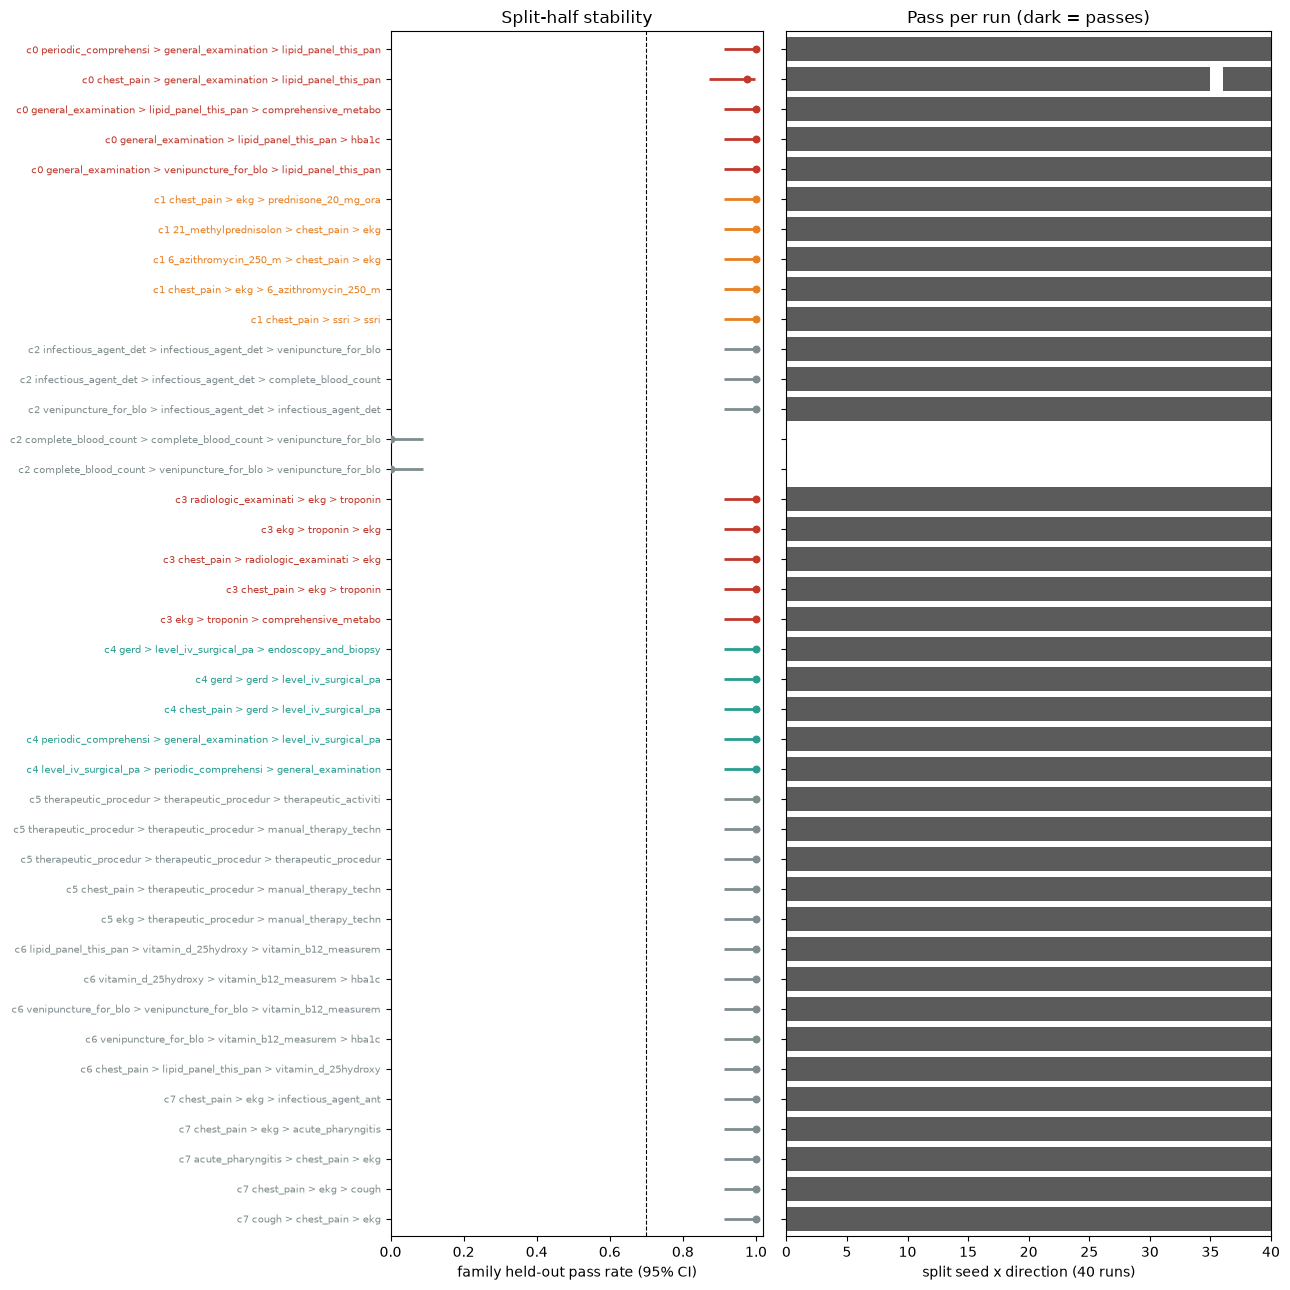

In [9]:
TOP_N = 5
GC = {CARD: '#C0392B', NONC: '#2A9D8F', RX: '#E67E22', BG: '#7F8C8D'}
short = lambda pat: ' > '.join(t.split('__')[0] for t in pat.split(' -> '))   # drop vocabulary / concept-id suffix
sel = []
for c, (_, name, role) in COMP.items():
    d = rows[c]
    if len(d):
        for i in np.flatnonzero(d.is_family_rep.to_numpy())[:TOP_N]:
            sel.append((c, i, role, f"c{c} {short(d.pattern.iloc[i])}"))
y = np.arange(len(sel))[::-1]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 0.28 * len(sel) + 1.8), sharey=True, gridspec_kw={'width_ratios': [1, 1.3]})
for yy, (c, i, role, lab) in zip(y, sel):
    d = rows[c].iloc[i]
    ax.hlines(yy, d.fam_holdout_rate_lo, d.fam_holdout_rate_hi, color=GC[role], lw=2)
    ax.scatter(d.fam_holdout_rate, yy, color=GC[role], s=22, zorder=3)
    ax2.imshow(ho_runs[c][i][None, :].astype(float), extent=(0, 40, yy - .4, yy + .4), aspect='auto', cmap='Greys', vmin=0, vmax=1.4)
ax.axvline(HO_MIN_RATE_LO, ls='--', c='k', lw=.8); ax.set_xlim(0, 1.02)
ax.set_xlabel('family held-out pass rate (95% CI)'); ax.set_yticks(y); ax.set_yticklabels([s[3] for s in sel], fontsize=7)
for t, s in zip(ax.get_yticklabels(), sel): t.set_color(GC[s[2]])
ax2.set_xlim(0, 40); ax2.set_ylim(-.6, len(sel) - .4); ax2.set_xlabel('split seed x direction (40 runs)')
ax.set_title('Split-half stability'); ax2.set_title('Pass per run (dark = passes)')
plt.tight_layout(); plt.show()

Each component now has **candidate motifs attached** — an ordered sequence, not just a set of
prevalent codes. Things to check:

- Does **c3** read as a workup path (troponin, EKG, imaging, angiography, in that order) and does
  **c0** read as a slower outpatient path (EKG, stress test, labs)?
- Do `anxiety` / `panic_attack` show up as a motif *before* troponin in **c3**, or only after it?
  Without visits, a "panic in the ED" story has to be carried by the workup codes alone.
- Do the background bundles (c2, c5, c6, c7) stay generic?

### A second lens: the Day 1 psych / cardiac probe

`chest_pain_labels()` is a direct rule-based split built from corroborating co-evidence. It is a
probe, not the structure: the labels come from `PSYCH_TAGS` / `CARDIAC_TAGS`, so a motif made of
those same tags partly rediscovers the label rule. Mined on a random 5,000-patient sample, since
every candidate is scanned against every sequence.


In [10]:
weak = eo.chest_pain_labels(events)
wl   = weak.set_index('person_id').chest_pain_label

# All patients here have chest_pain by cohort construction, so no filtering needed. LOCAL mining on a
# fixed random sample: candidates x sequences scans are the cost on a cohort this size.
rng   = np.random.default_rng(0)
samp  = rng.choice(len(db), min(5_000, len(db)), replace=False)
db_s  = [db[i] for i in samp]
y_s   = np.array([wl.get(pids[i], 'unlabelled') for i in samp])
print("sampled patients:", len(db_s),
      "  labelled:", int((y_s != 'unlabelled').sum()),
      "  ", dict(zip(*np.unique(y_s, return_counts=True))))

pats_cp = prefixspan(db_s, max(3, int(0.08 * len(db_s))), max_len=4)
C_cp = [tuple(p) for p in pats_cp[pats_cp.pattern.map(len) >= 3]
        .sort_values(['support', 'pattern'], ascending=[False, True]).head(60).pattern]

for g in ['psych', 'cardiac']:
    print(f"\n=== {g} evidence")
    display(discriminative(y_s == g, C_cp, sequences_db=db_s, min_in=0.10).head(6))


chest_pain patients: 139416   labelled: 64289   both-evidence (dropped): 34411   no-evidence (dropped): 40716
sampled patients: 5000   labelled: 2347    {np.str_('cardiac'): np.int64(1252), np.str_('psych'): np.int64(1095), np.str_('unlabelled'): np.int64(2653)}

=== psych evidence


,pattern,sup_in,sup_out,lift
0,chest_pain -> venipuncture_for_blo__procedure_...,0.412,0.451,0.9
1,general_examination___procedure__4036803 -> ve...,0.374,0.400,0.9
2,venipuncture_for_blo__procedure__4102442 -> li...,0.386,0.432,0.9
3,venipuncture_for_blo__procedure__4102442 -> li...,0.391,0.461,0.9
4,venipuncture_for_blo__procedure__4102442 -> ve...,0.395,0.462,0.9
5,venipuncture_for_blo__procedure__4102442 -> ve...,0.413,0.478,0.9



=== cardiac evidence


,pattern,sup_in,sup_out,lift
0,chest_pain -> ekg -> complete_blood_count__pro...,0.723,0.434,1.7
1,chest_pain -> ekg -> comprehensive_metabo__pro...,0.692,0.435,1.6
2,chest_pain -> ekg -> comprehensive_metabo__pro...,0.607,0.370,1.6
3,ekg -> comprehensive_metabo__procedure__366190...,0.669,0.428,1.6
4,chest_pain -> ekg -> ekg,0.599,0.399,1.5
5,chest_pain -> ekg -> venipuncture_for_blo__pro...,0.527,0.346,1.5


**This is the deliverable.** Ordered patterns, with in-group and out-group support, that read
as sentences. No transformer, no embeddings, no non-commercial licence to negotiate.

## 3 · Interval relations — when order is not enough

Order says "A before B." It does not say "A the same week" versus "A two years before B,"
which is the actual dx_9487 discriminator: is the anxiety history old and unrelated, or did
a cardiac workup follow within days. Allen's interval algebra defines 13 relations; for
point events on dates, a **signed gap** carries most of the value.

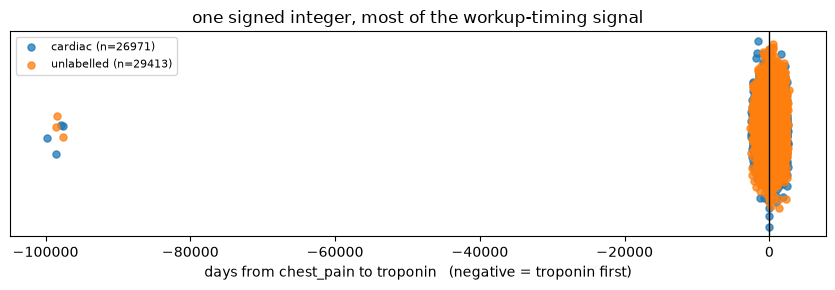

,count,mean,50%
chest_pain_label,,,
cardiac,26971.0,65.0,0.0
unlabelled,29413.0,97.0,0.0


In [11]:
gaps = eo.signed_gap(events, 'chest_pain', 'troponin')
gaps = gaps.merge(weak, on='person_id', how='left')
gaps['chest_pain_label'] = gaps['chest_pain_label'].fillna('unlabelled')

plt.figure(figsize=(8.5, 3))
for name, g in gaps.groupby('chest_pain_label'):
    plt.scatter(g.days_a_to_b, np.random.normal(0, .05, len(g)),
                s=26, alpha=.75, label=f"{name} (n={len(g)})")
plt.axvline(0, c='k', lw=1); plt.yticks([])
plt.xlabel('days from chest_pain to troponin   (negative = troponin first)')
plt.legend(fontsize=8); plt.title('one signed integer, most of the workup-timing signal')
plt.tight_layout(); plt.show()

display(gaps.groupby('chest_pain_label').days_a_to_b
            .describe()[['count', 'mean', '50%']].round(0))

**One signed integer.** Worth remembering the next time the conversation turns to four weeks
of GPU pretraining.

Two cautions on real data. This feature is only meaningful where lookback covers the earlier
event — otherwise you are measuring enrolment, not biology. And for patients with no
troponin at all the feature is NULL, which is not the same as zero; carry an explicit
`no_workup_in_lookback` flag rather than imputing (this is exactly what
`cardiac_workup_outcome()` does formally in Day 5).



### 3b · Does psych evidence come before or after troponin?

Motif mining only surfaces patterns above a support floor, and psychiatric care is a minority inside
every bundle, so it can miss exactly this question. This asks it directly, with no floor: for each
patient with both, the days from their first psych evidence to their first troponin.

- **Psych evidence** = an anxiety or panic diagnosis, or a psychiatric evaluation / psychotherapy code
  (`psych_eval_therapy`). SSRIs and benzodiazepines are left out: they are prescribed for many reasons.
- Positive = psych evidence **first**, then troponin. Negative = troponin first.
- Patients with psych evidence and no troponin are not in this comparison (no workup in the data).
- Only meaningful where history covers the earlier event, as in section 3.


,n,psych first %,same day %,troponin first %,median days
ALL (psych + troponin),27046.0,57.2,7.4,35.4,108.0
"c3 acute / ED workup (troponin, radio",6361.0,52.7,7.9,39.4,27.0
"c2 women's health (gyn exam, pregnanc",4349.0,61.6,6.1,32.3,185.0
c0 outpatient cardiometabolic / preve,3780.0,51.7,9.7,38.6,12.0
c5 musculoskeletal / physical therapy,3657.0,61.7,4.9,33.4,221.0
"c1 prescriptions (antibiotics, steroi",3325.0,56.8,9.0,34.2,113.0
"c6 nutrition + endocrine labs (B12, D",2671.0,59.2,7.0,33.8,130.0
c7 acute respiratory infection,1751.0,60.4,6.9,32.8,173.0
"c4 GI + cancer screening (GERD, endos",1152.0,61.6,6.3,32.0,253.0


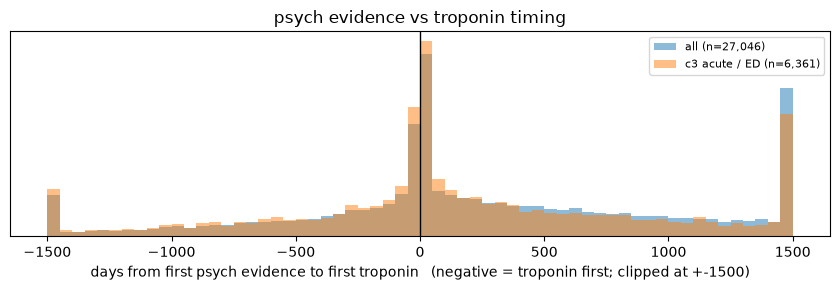

In [12]:
PSYCH = ['anxiety', 'panic_attack', 'psych_eval_therapy']
ev    = events[['person_id', 'event_date', 'tag']]                  # no copy of the full frame
first = lambda tags: ev.loc[ev.tag.isin(tags)].groupby('person_id').event_date.min()

both = pd.concat([first(PSYCH).rename('psych'), first(['troponin']).rename('trop')], axis=1).dropna()
both['days_psych_to_trop'] = (both.trop - both.psych).dt.days
both['bundle'] = pd.Series(comp, index=pids).reindex(both.index)
both = both[both.bundle >= 0]                                   # drop patients with no assigned bundle

def timing(d):
    g = d.days_psych_to_trop
    return pd.Series({'n': len(d), 'psych first %': round((g > 0).mean() * 100, 1),
                      'same day %': round((g == 0).mean() * 100, 1),
                      'troponin first %': round((g < 0).mean() * 100, 1),
                      'median days': g.median()})

tab = both.groupby('bundle').apply(timing)
tab.index = [f"c{int(b)} {COMP[int(b)][1][:34]}" for b in tab.index]
tab.loc['ALL (psych + troponin)'] = timing(both)
display(tab.sort_values('n', ascending=False))

c3d = both[both.bundle == 3].days_psych_to_trop
plt.figure(figsize=(8.5, 3))
plt.hist(both.days_psych_to_trop.clip(-1500, 1500), bins=60, alpha=.5, density=True, label=f"all (n={len(both):,})")
plt.hist(c3d.clip(-1500, 1500), bins=60, alpha=.5, density=True, label=f"c3 acute / ED (n={len(c3d):,})")
plt.axvline(0, c='k', lw=1); plt.yticks([])
plt.xlabel('days from first psych evidence to first troponin   (negative = troponin first; clipped at +-1500)')
plt.legend(fontsize=8); plt.title('psych evidence vs troponin timing')
plt.tight_layout(); plt.show()


## 4 · Trajectory graph — the readable artifact

Aggregate consecutive transitions into a weighted directed graph. This is the closest thing
to a chest-pain triage flowchart, but derived from observed transitions rather than a
guideline document — Ethos has no chest-pain ruleset to start from, so the agreed method is
to start from the data and check clinical plausibility afterwards.

139416 chest pain patients
13 nodes, 79 edges


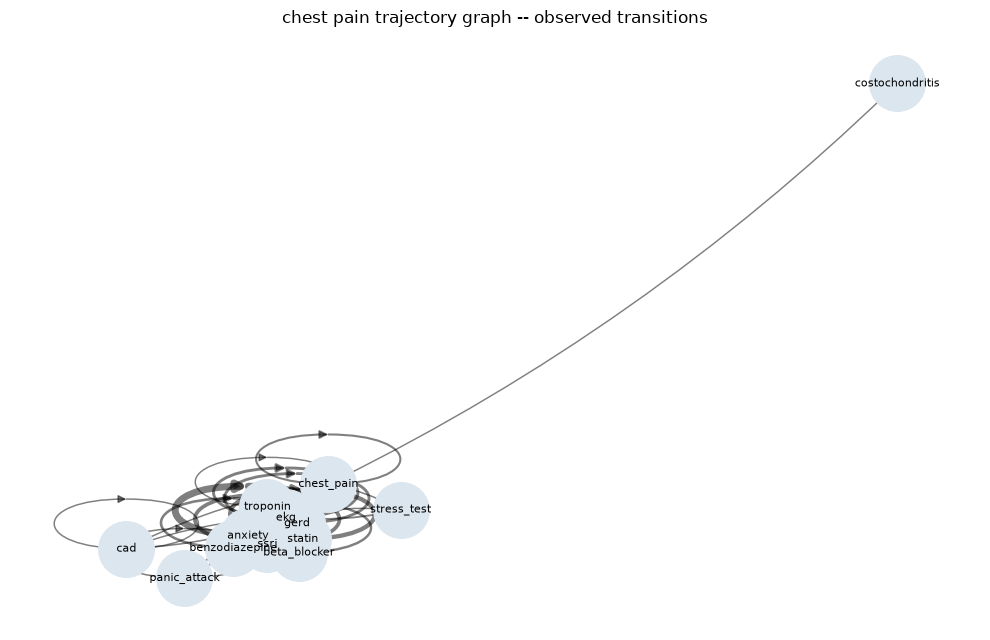

In [13]:
import networkx as nx

FOCUS = {'chest_pain', 'ekg', 'troponin', 'stress_test',
         'coronary_angio', 'beta_blocker', 'statin', 'cad',
         'anxiety', 'panic_attack', 'ssri', 'benzodiazepine',
         'gerd', 'costochondritis'}

db_cp = [[c for c in seqs[p] if c in FOCUS] for p in pids if 'chest_pain' in seqs[p]]
print(f"{len(db_cp)} chest pain patients")

cnt = collections.Counter()
for s in db_cp:
    for u, v in zip(s, s[1:]):
        cnt[(u, v)] += 1
G = nx.DiGraph()
for (u, v), w in cnt.items():
    if w >= max(5, int(0.02 * len(db_cp))):
        G.add_edge(u, v, weight=w)
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges")

plt.figure(figsize=(10, 6.5))
pos = nx.spring_layout(G, seed=3, k=1.1)
w   = np.array([G[u][v]['weight'] for u, v in G.edges()], dtype=float)
nx.draw_networkx_nodes(G, pos, node_size=1600, node_color='#DCE6EF')
nx.draw_networkx_labels(G, pos, font_size=8)
nx.draw_networkx_edges(G, pos, width=1 + 4 * w / w.max(), alpha=.5,
                       arrowsize=12, connectionstyle='arc3,rad=0.08')
plt.title('chest pain trajectory graph -- observed transitions')
plt.axis('off'); plt.tight_layout(); plt.show()

Two arms should be visible out of `chest_pain`: one through troponin, stress test,
angiography and statins; the other through anxiety, panic_attack, ssri and benzodiazepine.
Whichever arm dominates numerically is the answer to the working hypothesis — let the graph
say which, rather than assuming.

## Exercises

1. Lower `MIN_SUP` to 1%. How many patterns, and is closed-pattern pruning enough?
2. Extend `prefixspan` to enforce a maximum time gap between consecutive items. Which
   patterns die? (This is the single highest-value extension for claims.)
3. Add `gerd` and `costochondritis` to the trajectory graph's `FOCUS` set with a lower edge
   threshold. Do either show up as a real third arm, or are they noise?
4. Re-run the whole notebook with `tag_events(..., fallback='drop')` so only curated
   codesets survive. Cleaner patterns, but what did you lose?
5. Write the top motif per group (psych, cardiac) as a named plain-English rule. **That
   list is the motif catalog** — the thing to actually put in front of RUW.

## Carry forward

A motif catalog for dx_9487 triage, obtained without a foundation model.

## 5 · Export — top-3 patterns table (Excel)
Top 3 highest-lift ordered patterns per component, with condensed concept names (vocabulary + code) and the hybrid columns. No *Full concept names* or *literature* columns. Written next to this notebook; needs `openpyxl`.

In [14]:
import re, itertools
try:
    import openpyxl
except ImportError as e:
    raise ImportError("pip install openpyxl in this kernel's environment, then rerun this cell") from e
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

import os; os.makedirs('outputs', exist_ok=True)
XLSX, TOPK = "outputs/Day3_v3_hybrid_top3_patterns_table.xlsx", 3
cdx = concept.drop_duplicates('concept_id').set_index('concept_id')

def _condense_name(n, limit=38):
    n = re.split(r' \(|;| This ', n)[0].strip()
    return n if len(n) <= limit else n[:limit].rsplit(' ', 1)[0] + '…'

def label(token):
    m = re.search(r'__(\d+)$', token)
    if m and int(m.group(1)) in cdx.index:
        r = cdx.loc[int(m.group(1))]
        return f"{_condense_name(r.concept_name)} [{r.vocabulary_id} {r.concept_code}]"
    return f"{token.replace('_', ' ')} [code group]"

def pattern_text(pattern):
    parts = []
    for t, g in itertools.groupby(pattern.split(' -> ')):
        n = len(list(g)); parts.append(label(t) + (f" ×{n}" if n > 1 else ""))
    return ' → '.join(parts)

HEAD = ['Care pattern', 'Patients in group', 'Group role', 'Rank (by lift)',
        'Typical order of care (condensed names, vocabulary + code)', 'Share of group with pattern',
        'Share of everyone else with pattern', 'Times as common (lift)', 'Held-out pass rate (family, 40 splits)',
        'Held-out pass rate, lower 95%', 'Order shown by dates?', 'Held-out verdict', 'FDR q (BH)']
data = []
for c, (_, name, role) in COMP.items():
    for rk, (_, r) in enumerate(hyb[c].head(TOPK).iterrows(), 1):
        data.append([name[0].upper() + name[1:], n_in[c], role.capitalize(), rk, pattern_text(r.pattern),
                     float(r.sup_in), float(r.sup_out), float(r.lift), float(r.fam_holdout_rate), float(r.fam_holdout_rate_lo),
                     'Same-day bundle' if r.same_day_bundle else 'Yes', r.holdout_verdict.capitalize(), float(r.q_fisher)])

F = lambda **k: Font(name='Arial', size=10, **k)
FILL = {'Holds': 'D6F0DE', 'Weak': 'F8D7D7', 'Same-day bundle': 'FBEFC9'}
thin = Side(style='thin', color='D0D5DB')
wb = openpyxl.Workbook(); ws = wb.active; ws.title = 'Top 3 patterns'
ws.append(HEAD)
for j in range(1, len(HEAD) + 1):
    h = ws.cell(1, j); h.font = Font(name='Arial', size=10, bold=True, color='FFFFFF')
    h.fill = PatternFill('solid', fgColor='334E68'); h.alignment = Alignment(wrap_text=True, vertical='center', horizontal='center')
ws.row_dimensions[1].height = 42
for row in data:
    ws.append(row)
for i in range(2, len(data) + 2):
    for j in range(1, len(HEAD) + 1):
        c_ = ws.cell(i, j); c_.font = F(bold=(j == 1)); c_.border = Border(bottom=thin)
        c_.alignment = Alignment(wrap_text=(j in (1, 3, 5)), vertical='top', horizontal='left' if j in (1, 3, 5) else 'center')
    for j in (6, 7, 9, 10): ws.cell(i, j).number_format = '0.0%'
    ws.cell(i, 8).number_format = '0.0'; ws.cell(i, 13).number_format = '0.000'
    for j in (11, 12):
        v = ws.cell(i, j).value
        if v in FILL:
            ws.cell(i, j).fill = PatternFill('solid', fgColor=FILL[v]); ws.cell(i, j).font = F(bold=True)
for j, w in enumerate([34, 11, 16, 8, 80, 12, 13, 11, 14, 14, 14, 12, 10], 1):
    ws.column_dimensions[get_column_letter(j)].width = w
ws.freeze_panes = 'B2'; ws.auto_filter.ref = f"A1:{get_column_letter(len(HEAD))}{len(data) + 1}"

notes = [
    "Notes",
    f"Source: Day 3 v3 hybrid (visit-pruned) chest-pain run, NMF k=8 groups (Day 1 v2). {len(db):,} patients. Group roles come from the Day 1 v2 loadings and are drafts needing expert sign-off.",
    f"Each component is mined on a random sample of at most 3,000 of its patients (its 60 most common ordered patterns of 3+ steps, each present in >={REL_SUP:.0%} of the sample); the 3 highest-lift patterns are listed. Several are variants of one pathway. Shares are from the mining sample.",
    "Times as common = (share inside group + 0.01) / (share outside + 0.01). Outside = random sample of 1,500 patients from other groups.",
    f"Held-out pass rate: {len(HO_SEEDS)} random 50/50 splits of the whole component x 2 directions = {2 * len(HO_SEEDS)} runs, scored on every patient; a run passes if, on the half not used, support is >= {REL_SUP:.0%} and the lower 95% bound of the odds ratio vs all other patients is >= {HO_MIN_OR:g}. Near-duplicate patterns are one family (a run passes if any member does). Holds = family lower 95% bound >= {HO_MIN_RATE_LO:.0%}.",
    f"Order shown by dates? 'Same-day bundle' = with each step required on a strictly later day, support falls below {SAME_DAY_RATIO:.0%} of its value under the table's ordering rule: the steps mostly occur together on one day, so the order is a tie-break, not evidence.",
    "FDR q = Benjamini-Hochberg q-value (Fisher exact, one-sided) across all motifs of all components.",
    "'×N' = the same concept appears N times in a row in the pattern. '[code group]' = a curated group of several codes. Ties are broken on the pattern text, so reruns give the same table.",
]
r0 = len(data) + 3
for k, t in enumerate(notes):
    ws.cell(r0 + k, 1, t).font = F(bold=(k == 0))
wb.save(XLSX)
print(f"wrote {os.path.abspath(XLSX)}  ({len(data)} rows, {len(HEAD)} columns)")
pd.DataFrame(data, columns=HEAD).iloc[:, [0, 3, 4, 8, 9, 10, 11]]

wrote /Users/esteban.correaagudelo/codeprojects/ethos_foundation_llm/nb/repr_learn_chestpain/Day3_v3_hybrid_top3_patterns_table.xlsx  (24 rows, 13 columns)


,Care pattern,Rank (by lift),"Typical order of care (condensed names, vocabulary + code)","Held-out pass rate (family, 40 splits)","Held-out pass rate, lower 95%",Order shown by dates?,Held-out verdict
0,Outpatient cardiometabolic / preventive workup...,1,Periodic comprehensive preventive… [CPT4 99396...,1.000,0.912,Yes,Holds
1,Outpatient cardiometabolic / preventive workup...,2,chest pain [code group] → General examination ...,0.975,0.871,Yes,Holds
2,Outpatient cardiometabolic / preventive workup...,3,General examination of patient [SNOMED 1626730...,1.000,0.912,Yes,Holds
3,"Prescriptions (antibiotics, steroids, NSAIDs, ...",1,chest pain [code group] → ekg [code group] → p...,1.000,0.912,Yes,Holds
4,"Prescriptions (antibiotics, steroids, NSAIDs, ...",2,{21 [RxNorm 762675] → chest pain [code group] ...,1.000,0.912,Yes,Holds
5,"Prescriptions (antibiotics, steroids, NSAIDs, ...",3,{6 [RxNorm 749783] → chest pain [code group] →...,1.000,0.912,Yes,Holds
6,"Women's health (gyn exam, pregnancy test, cyto...",1,Infectious agent detection by nucleic… [CPT4 8...,1.000,0.912,Yes,Holds
7,"Women's health (gyn exam, pregnancy test, cyto...",2,Infectious agent detection by nucleic… [CPT4 8...,1.000,0.912,Yes,Holds
8,"Women's health (gyn exam, pregnancy test, cyto...",3,Venipuncture for blood test [SNOMED 28520004] ...,1.000,0.912,Same-day bundle,Holds
9,"Acute / ED workup (troponin, radiology, inject...",1,"Radiologic examination, chest [CPT4 71045] → e...",1.000,0.912,Same-day bundle,Holds
